# C1: lateral-colour model refit on DR10 000-063 (after the two-line DCR and the rebuilt CCD maps)

Same model as before (`run/lateral-model.ipynb`, approved 2026-10-10): per band,
shift = (c - c0) x [Px(u, v), Py(u, v)], c = g - i, 2-D polynomials of total order 3 in focal-plane position, subtracted
from the CCD-map-corrected position. What changes:
- **data**: Gaia stars from all 000-063 slices (the B1 sample: sigma < 10 mas, with colour, not bright/saturated) instead
  of 200 archive bricks of 060-063 processed with the old DCR and the 2024 CCD maps;
- **pivot c0**: the CCD maps remove the shift of the median star in each bin, so the lateral term should vanish at the
  median colour of the stars the maps were built from; c0 is set to that median (was 1.642 from the archive sample);
- **colour**: g - i measured, or from g - z (colours.py), as the pipeline now uses.

Validation: fit on half of the bricks, robust per-axis scatter on the other half, per band and colour bin, for no
lateral correction, the current coefficients, and the refit. The final cell refits on all bricks and writes
`py_files/lateral_model_poly3_candidate.json`, to replace `lateral_model_poly3.json` (read by `brick_lateralmaps.py`).

In [1]:
import os, sys, json, datetime
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import plot_style as ps, ringmap_build as rb
from py_files.brick_ringmaps import RINGMAPS_PATH   # the maps the pipeline applies
ps.apply()
BRICK_FRACTION = 0.15
PIX_MAS = 262.
BANDS = 'griz'
rsig = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
S, ccds = rb.load_samples(BRICK_FRACTION, seed=3)
ok = np.isfinite(S['gi']) & (S['gi'] > -0.5) & (S['gi'] < 4)
S = {k: (v[ok] if isinstance(v, np.ndarray) and len(v) == len(ok) else v) for k, v in S.items()}
S['ccds'] = ccds
# residual after DCR (already removed in the sample) and the new CCD maps, in pixels
NEW = rb.old_maps(RINGMAPS_PATH)
mx, my = rb.apply_maps(S, np.ones(len(S['x']), bool), NEW, 16)
S['res_x'], S['res_y'] = S['dx'] - mx, S['dy'] - my
S['rm_x'], S['rm_y'] = S['x'] + S['res_x'], S['y'] + S['res_y']     # = rm_full_fit_x/y
OLD = json.load(open('../py_files/lateral_model_poly3.json'))
cp = np.array([OLD['crpixes'].get(c, (np.nan, np.nan)) for c in ccds])[S['ccd_i']]
fp = np.isfinite(cp[:, 0])
S = {k: (v[fp] if isinstance(v, np.ndarray) and len(v) == len(fp) else v) for k, v in S.items()}
cp = cp[fp]
S['u'] = (S['rm_x'] - cp[:, 0]) / OLD['fp_scale']; S['v'] = (S['rm_y'] - cp[:, 1]) / OLD['fp_scale']
S['test'] = (S['brickid'].astype(np.int64) * 2654435761 % 2**32) % 2 == 1
C0 = float(np.median(S['gi']))
print(f"{len(S['u']):,} epochs from {len(np.unique(S['brickid'])):,} bricks; median g - i of the map stars: {C0:.3f} "
      f"(per band: " + ', '.join(f"{b} {np.median(S['gi'][S['band'] == j]):.3f}" for j, b in enumerate(BANDS)) + f"); old c0 {OLD['c0']}")

43,776,212 epochs from 12,021 bricks; median g - i of the map stars: 1.469 (per band: g 0.926, r 1.259, i 1.704, z 1.996); old c0 1.642


In [2]:
# Fit (same design and robust fit as the approved model), on the training half
TERMS = OLD['poly_terms']
def design(u, v, dc):
    P = np.stack([u**i * v**j for i, j in TERMS], 1) * dc[:, None]
    Z = np.zeros_like(P)
    return np.hstack([P, Z]), np.hstack([Z, P])

def remove_offsets(m):
    rx, ry = S['res_x'][m].copy(), S['res_y'][m].copy()
    key = S['map_i'][m]
    order = np.argsort(key, kind='stable'); u_, st = np.unique(key[order], return_index=True)
    for idx in np.split(order, st[1:]):
        rx[idx] -= np.median(rx[idx]); ry[idx] -= np.median(ry[idx])
    return rx, ry

def robust_lstsq(A, y, n_iter=6):
    w = np.ones(len(y), bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[w], y[w], rcond=None)[0]
        r = y - A @ coef
        w = np.abs(r) < 3 * rsig(r[w])
    return coef

def fit(m, c0):
    rx, ry = remove_offsets(m)
    Ax, Ay = design(S['u'][m], S['v'][m], S['gi'][m] - c0)
    return robust_lstsq(np.vstack([Ax, Ay]), np.concatenate([rx, ry]))

def shift(coef, m, c0):
    Ax, Ay = design(S['u'][m], S['v'][m], S['gi'][m] - c0)
    return Ax @ coef, Ay @ coef

FITS = {b: {'refit, old c0': fit(~S['test'] & (S['band'] == j), OLD['c0']),
            'refit, median c0': fit(~S['test'] & (S['band'] == j), C0)} for j, b in enumerate(BANDS)}
print('fitted')

fitted


In [3]:
# Held-out comparison: per band and colour bin, robust per-axis scatter (mas)
cbins = {'blue g-i<0.9': (-0.5, 0.9), 'mid': (0.9, 2.3), 'red g-i>2.3': (2.3, 4)}
rows = []
for j, b in enumerate(BANDS):
    for name, (lo, hi) in cbins.items():
        m = S['test'] & (S['band'] == j) & (S['gi'] >= lo) & (S['gi'] < hi)
        if m.sum() < 1000: continue
        cand = {'none': (0., 0.), 'current': shift(np.array(OLD['coef'][b]), m, OLD['c0'])}
        cand.update({k: shift(c, m, OLD['c0'] if 'old' in k else C0) for k, c in FITS[b].items()})
        rows.append((b, name, m.sum(), {k: PIX_MAS * np.sqrt((rsig(S['res_x'][m] - dx)**2 + rsig(S['res_y'][m] - dy)**2) / 2)
                                         for k, (dx, dy) in cand.items()}))
keys = list(rows[0][3])
print(f"{'band':4s} {'colour':13s} {'N':>9s} " + ''.join(f'{k:>18s}' for k in keys))
for b, name, n, d in rows:
    print(f'{b:4s} {name:13s} {n:9,d} ' + ''.join(f'{d[k]:18.2f}' for k in keys))
print('all colours:')
for j, b in enumerate(BANDS):
    m = S['test'] & (S['band'] == j)
    cand = {'none': (0., 0.), 'current': shift(np.array(OLD['coef'][b]), m, OLD['c0'])}
    cand.update({k: shift(c, m, OLD['c0'] if 'old' in k else C0) for k, c in FITS[b].items()})
    print(f'{b:4s} ' + ''.join(f"{k}: {PIX_MAS * np.sqrt((rsig(S['res_x'][m] - dx)**2 + rsig(S['res_y'][m] - dy)**2) / 2):.2f}   " for k, (dx, dy) in cand.items()))

band colour                N               none           current     refit, old c0  refit, median c0
g    blue g-i<0.9  2,034,028              13.44             12.90             12.82             12.80
g    mid           1,486,848              11.07             11.01             10.99             10.85
g    red g-i>2.3     614,928              12.84             11.57             11.64             11.44
r    blue g-i<0.9  2,633,367              12.04             12.02             12.01             12.00
r    mid           2,193,246              10.09             10.09             10.08             10.09
r    red g-i>2.3   1,621,170              10.50             10.40             10.39             10.39
i    blue g-i<0.9  1,891,431              10.42             10.43             10.40             10.40
i    mid           1,826,167               9.22              9.25              9.21              9.21
i    red g-i>2.3   1,873,119               9.59              9.59              9.5

g    none: 12.47   current: 11.97   refit, old c0: 11.93   refit, median c0: 11.84   


r    none: 10.93   current: 10.91   refit, old c0: 10.88   refit, median c0: 10.88   


i    none: 9.73   current: 9.88   refit, old c0: 9.71   refit, median c0: 9.71   


z    none: 9.27   current: 9.27   refit, old c0: 9.26   refit, median c0: 9.26   


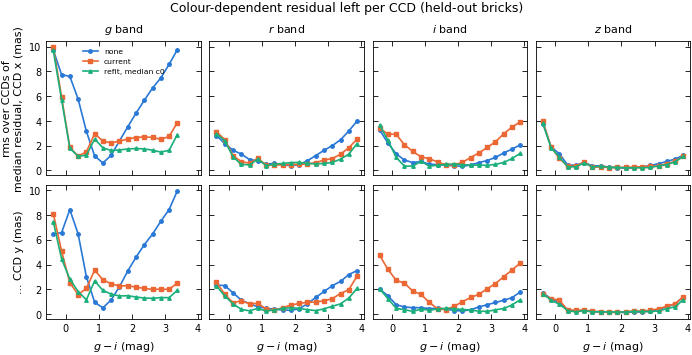

In [4]:
# Remaining colour dependence: held-out residual vs colour, binned medians, per band and axis
cb = np.linspace(-0.5, 4, 19); cc = 0.5 * (cb[1:] + cb[:-1])
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 3.6), sharex=True, sharey=True, constrained_layout=True)
for j, b in enumerate(BANDS):
    m = S['test'] & (S['band'] == j)
    rx, ry = remove_offsets(m)
    cand = {'none': (0. * rx, 0. * ry), 'current': shift(np.array(OLD['coef'][b]), m, OLD['c0']),
            'refit, median c0': shift(FITS[b]['refit, median c0'], m, C0)}
    ib = np.digitize(S['gi'][m], cb) - 1
    for row, (comp, r) in enumerate((('x', rx), ('y', ry))):
        for k, (name, (dx, dy)) in enumerate(cand.items()):
            d = dx if comp == 'x' else dy
            res = (r - (d - np.median(d))) * PIX_MAS
            # median over the focal plane is ~0 by construction; use the rms over CCDs of per-CCD medians instead
            prof = []
            for q in range(len(cc)):
                s = ib == q
                if s.sum() < 2000: prof.append(np.nan); continue
                key = S['ccd_i'][m][s]
                meds = [np.median(res[s][key == c]) for c in np.unique(key) if np.sum(key == c) > 50]
                prof.append(np.sqrt(np.mean(np.square(meds))))
            axes[row, j].plot(cc, prof, marker=ps.MARKERS[k], ms=2.5, color=ps.SERIES[k], label=name)
        axes[0, j].set_title(f'${b}$ band')
    axes[1, j].set_xlabel(r'$g-i$ (mag)')
axes[0, 0].set_ylabel('rms over CCDs of\nmedian residual, CCD x (mas)'); axes[1, 0].set_ylabel('... CCD y (mas)')
axes[0, 0].legend(fontsize=5.5)
fig.suptitle('Colour-dependent residual left per CCD (held-out bricks)')
plt.savefig('plots/lateral_refit_colour_residual.pdf')

## Final fit on all bricks -> `py_files/lateral_model_poly3_candidate.json`

Written as a candidate; adopted by copying it over `lateral_model_poly3.json` (read by `brick_lateralmaps.py`) once the
held-out comparison above shows it helps.

In [5]:
FINAL = {b: fit(S['band'] == j, C0).tolist() for j, b in enumerate(BANDS)}
model = dict(OLD)
model.update({'c0': round(C0, 3), 'coef': FINAL,
              'fit': {'notebook': 'run/lateral-model-dr10.ipynb', 'date': str(datetime.date.today()),
                      'n_bricks': int(len(np.unique(S['brickid']))), 'n_measurements': int(len(S['u'])),
                      'selection': 'B1 sample (ringmap_build.py): Gaia stars, sigma < 10 mas, dqmask == 0, measured, '
                                   'g - i measured or from g - z, -0.5 < g - i < 4, not BRIGHT/SATURATED; residual after '
                                   'the two-line DCR and ringmaps-dr10.fits; c0 = median g - i of these stars'}})
json.dump(model, open('../py_files/lateral_model_poly3_candidate.json', 'w'), indent=1)
print('wrote ../py_files/lateral_model_poly3_candidate.json; c0 =', model['c0'])
for j, b in enumerate(BANDS):
    m = S['band'] == j
    dx, dy = shift(np.array(FINAL[b]), m, C0)
    print(f'  {b}: rms applied shift {PIX_MAS * np.sqrt(np.mean(dx**2 + dy**2)):.2f} mas')

wrote ../py_files/lateral_model_poly3_candidate.json; c0 = 1.469


  g: rms applied shift 6.33 mas


  r: rms applied shift 1.57 mas


  i: rms applied shift 0.88 mas


  z: rms applied shift 0.36 mas
